# Monte Carlo 方法示例代码

本文通过 Python 数值实验演示 Monte Carlo 方法的基本原理，示例编号与配套讲义保持一致，语言采用python进行编写，必要的三方库为 `numpy` 和 `matplotlib` 。实验内容包括有保底机制的抽卡模拟、随机变量生成、Monte Carlo 积分，以及对偶变量法、分层抽样和重要性采样。通过观察估计量的分布、方差与均方根误差（RMSE），理解样本量和采样方法对估计精度的影响。

本次代码验证环境为：

- Python：3.12.4
- NumPy：1.26.4
- Matplotlib：3.11.1

为便于复现，统一设置固定随机种子 `20260930`，并按 notebook 的顺序执行实验。随机生成函数的 `rng` 参数默认为 `None`，此时沿用 NumPy 的全局随机状态；需要独立控制随机数时，可传入自行初始化的 `numpy.random.Generator`。复现实验时，还应保持代码、依赖版本及执行顺序一致。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 统一种子为固定整数；不传 rng 的函数仍使用这个全局随机状态。
SEED = 20260930
np.random.seed(SEED)


## 1.1 有保底机制的抽卡

例 1.2. 设有以下抽卡过程：
- 每次抽取相互独立，成功概率由当前保底状态决定。
- 初始概率为2%，若连续50抽没出六星，则从第51抽起每抽增加2%的六星概率，直至获得六星。
- 每一次获得六星时都有35%的概率是当期六星，且出当期六星的概率互相独立。
- 若前299抽没有出当期六星，则第300抽固定为当期六星。

试求第一次出当期六星的期望抽数。

In [3]:
def draw_card(
    p: float=0.02,
    soft_pity: int=50,
    increment: float=0.02,
    featured_p: float=0.35,
    hard_pity: int=300,
    rng: np.random.Generator | None = None,
) -> int:

    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    # 当前连续未出六星的次数；获得六星后归零。
    draws_without_six_star = 0 #未出六星抽数

    for draw_index in range(hard_pity):
        six_star_probability = p

        # 若连续没六星的抽数超过软保底，那么增加概率
        if draws_without_six_star >= soft_pity:
            six_star_probability += increment * (draws_without_six_star - soft_pity + 1)

        # 检测是否出六星
        if random_source.binomial(1, six_star_probability):
            draws_without_six_star = 0 #重置未出六星抽数

            # 检测是否是当期六星
            if random_source.binomial(1, featured_p):
                return draw_index + 1

        else:
            draws_without_six_star += 1
            
    # 之前未返回时，按硬保底规则记录首次当期六星抽数。
    return hard_pity


def repeat_draw(
    repeat_times: int,
    p: float=0.02,
    soft_pity: int=50,
    increment: float=0.02,
    featured_p: float=0.35,
    hard_pity: int=300,
    rng: np.random.Generator | None = None,
) -> np.ndarray:

    # 每个元素是一轮完整抽卡过程的首次当期六星抽数。
    draw_counts = []
    for replication_index in range(repeat_times):
        draw_counts.append(
            draw_card(p, soft_pity, increment, featured_p, hard_pity, rng=rng)
        )

    return np.array(draw_counts)

def frequency_histogram(data: np.ndarray, xlabel: str="", title: str="", bins: int=30):
    plt.hist(
        data,
        bins=bins,
        color="lightblue"
    )
    plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']  # 微软雅黑
    plt.rcParams['axes.unicode_minus'] = False
    plt.xlabel(xlabel)
    plt.ylabel("频数")
    plt.title(title)
    plt.show()


1000次平均：101.287
10000次平均：96.6991
100000次平均：95.86326


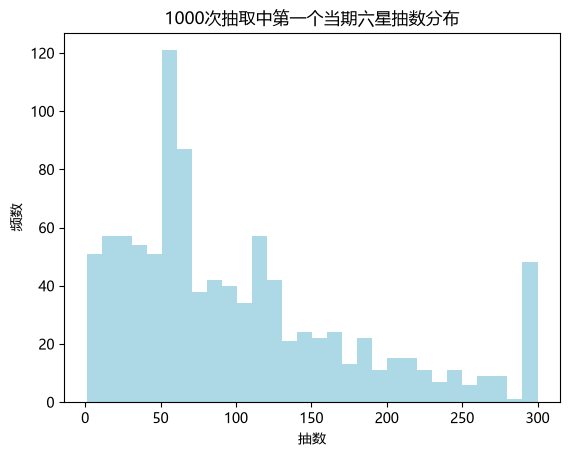

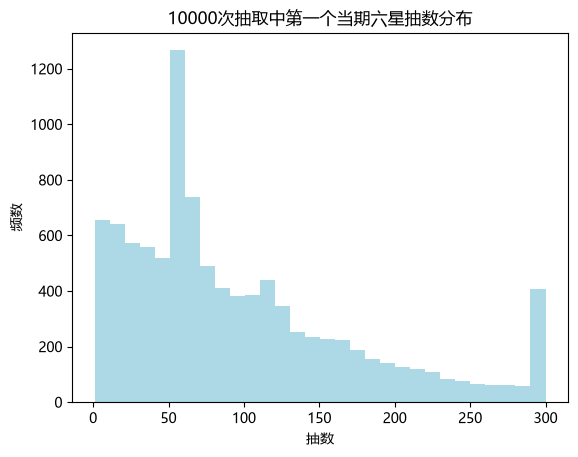

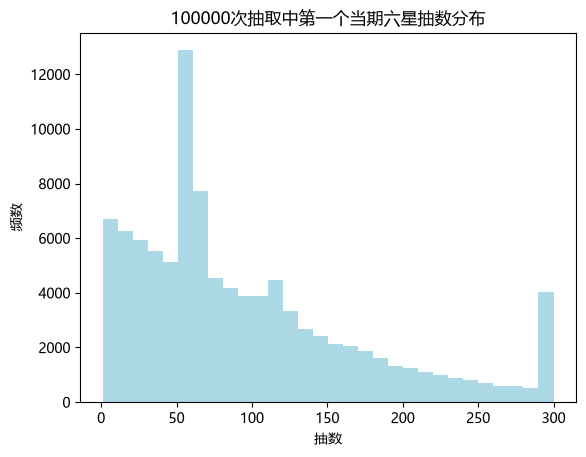

In [4]:
if __name__ == "__main__":
    draw_counts_1000 = repeat_draw(1000)
    draw_counts_10000 = repeat_draw(10000)
    draw_counts_100000 = repeat_draw(100000)

    print(f"1000次平均：{np.mean(draw_counts_1000)}")
    print(f"10000次平均：{np.mean(draw_counts_10000)}")
    print(f"100000次平均：{np.mean(draw_counts_100000)}")

    frequency_histogram(draw_counts_1000, "抽数", "1000次抽取中第一个当期六星抽数分布")
    frequency_histogram(draw_counts_10000, "抽数", "10000次抽取中第一个当期六星抽数分布")
    frequency_histogram(draw_counts_100000, "抽数", "100000次抽取中第一个当期六星抽数分布")


### 附录：当期六星的出率和硬保底对抽数分布的影响

特别地，我们可以观察参数 `featured_p` 和 `hard_pity` 对抽数分布的影响。固定总模拟次数为10000次，我们观察以下参数的抽数分布：
- `featured_p = 0.35, hard_pity=300`
- `featured_p = 0.5, hard_pity=300`
- `featured_p = 0.5, hard_pity=120`

featured_p = 0.35, hard_pity=300平均：94.1408
featured_p = 0.5, hard_pity=300平均：68.5209
featured_p = 0.5, hard_pity=120平均：60.991


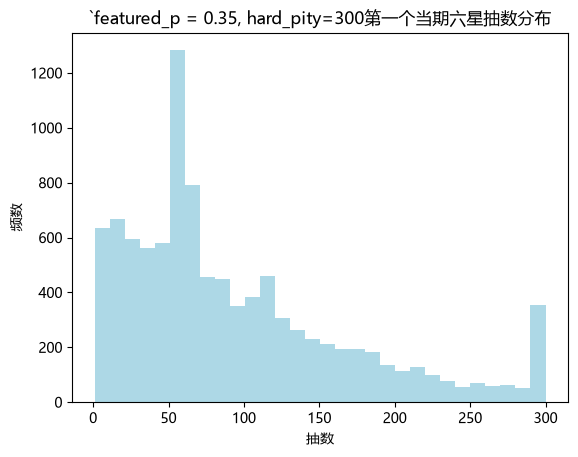

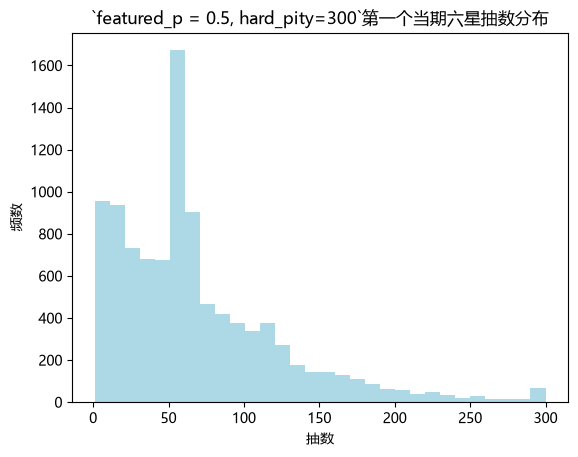

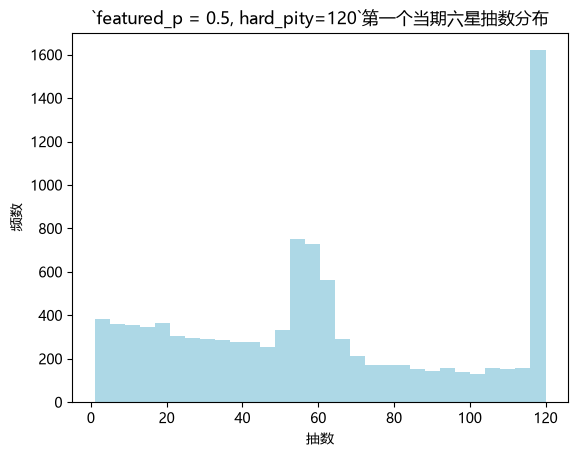

In [5]:
if __name__ == "__main__":
    draw_counts_limited = repeat_draw(10000)
    draw_counts_normal = repeat_draw(10000, featured_p=0.5)
    draw_counts_crossover = repeat_draw(10000, featured_p=0.5, hard_pity=120)

    print(f"featured_p = 0.35, hard_pity=300平均：{np.mean(draw_counts_limited)}")
    print(f"featured_p = 0.5, hard_pity=300平均：{np.mean(draw_counts_normal)}")
    print(f"featured_p = 0.5, hard_pity=120平均：{np.mean(draw_counts_crossover)}")

    frequency_histogram(draw_counts_limited, "抽数", "`featured_p = 0.35, hard_pity=300第一个当期六星抽数分布")
    frequency_histogram(draw_counts_normal, "抽数", "`featured_p = 0.5, hard_pity=300`第一个当期六星抽数分布")
    frequency_histogram(draw_counts_crossover, "抽数", "`featured_p = 0.5, hard_pity=120`第一个当期六星抽数分布")


## 1.3 Monte Carlo 估计量的中心极限定理

仍然以例1.2的抽卡过程为例。独立重复多次实验，求得一定模拟次数下Monte Carlo估计量的近似分布。

In [6]:
import numpy as np

def get_distribution(
    number_of_samples: int, #总共重复多少次实验
    simulation_times: int, #每个Monte Carlo估计量需要的模拟次数
    p: float=0.02,
    soft_pity: int=50,
    increment: float=0.02,
    featured_p: float=0.35,
    hard_pity: int=300,
    rng: np.random.Generator | None = None,
):
    
    # number_of_samples 是独立重复次数 R；simulation_times 是每次样本数 N。
    mean_estimates = []
    for replication_index in range(number_of_samples):
        mean_estimates.append(
            np.mean(repeat_draw(
                simulation_times, p, soft_pity, increment, featured_p, hard_pity, rng=rng
            ))
        )

    return mean_estimates


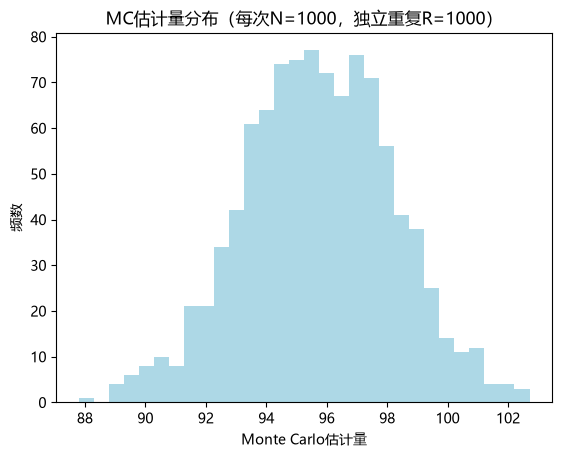

In [7]:
if __name__ == "__main__":
    mean_estimates = get_distribution(1000, 1000)
    frequency_histogram(mean_estimates, "Monte Carlo估计量", "MC估计量分布（每次N=1000，独立重复R=1000）")


## 1.4 Monte Carlo 估计量 RMSE 的收敛阶

仍然以1.2的抽卡过程为例。我们分别计算10/30/100/300/1000/3000次模拟次数下的Monte Carlo估计量。每个实验重复500次得到近似分布。

由于 Monte Carlo 估计量是无偏的，在二阶矩有限的情况下可以用多次独立实验所得估计量的样本标准差估计 RMSE。

为得到 RMSE 和模拟次数 $n$ 的指数关系，我们可以画出 RMSE 关于 $n$ 的 log-log 图，观察其斜率。

这里我们利用样本的方差近似估计RMSE。

In [8]:
def plot(
    x: np.ndarray,
    y: np.ndarray,
    figtype: str="default", #图像类型，可以画标准折线图和log-log图，参数："default", "loglog"
    label: str | list[str]="", #数据标签，可以是字符串或字符串列表
    xlabel: str="", #x轴标签
    ylabel: str="", #y轴标签
    title: str="",
    fit_slope: bool=False #是否需要拟合斜率
):
    plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']  # 微软雅黑
    plt.rcParams['axes.unicode_minus'] = False
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    #单组数据转成二维数组，每一行对应一条折线
    if y.ndim == 1:
        y = y[None, :]

    if y.ndim != 2:
        raise ValueError("y 必须是一组数据或多组数据")

    if x.ndim != 1 or y.shape[1] != len(x):
        raise ValueError("每组数据的长度必须与一维数组 x 相同")

    #字符串标签用于所有折线；列表则分别对应各条折线
    if isinstance(label, str):
        labels = [label] * len(y)
    else:
        labels = list(label)
        if len(labels) != len(y):
            raise ValueError("标签数量必须与折线数量一致")

    if figtype not in ("default", "loglog"):
        raise ValueError("figtype 必须是 'default' 或 'loglog'")

    if figtype == "loglog" and (
        np.any(x <= 0) or np.any(y <= 0)
    ):
        raise ValueError("log-log 图要求 x 和 y 的值均大于零")

    plt.figure(figsize=(7,5))

    if figtype == "loglog":
        draw_curve = plt.loglog
    else:
        draw_curve = plt.plot
        plt.ticklabel_format(
            axis="y",
            style="sci",
            scilimits=(-3,3)
        )

    #分别绘制每条折线
    for curve_values, curve_label in zip(y, labels):
        line, = draw_curve(x, curve_values, marker='o', label=curve_label)

        if fit_slope:
            if figtype == "loglog":
                slope, intercept = np.polyfit(
                    np.log(x), np.log(curve_values), 1
                )
                fitted_values = np.exp(intercept) * x**slope
            else:
                slope, intercept = np.polyfit(x, curve_values, 1)
                fitted_values = intercept + slope * x

            #拟合线与对应的数据折线使用相同颜色
            draw_curve(
                x, fitted_values,
                color=line.get_color(),
                label=f"{curve_label + ': ' if curve_label else ''}Fit slope = {slope:.2f}",
                linestyle="--"
            )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    if any(labels) or fit_slope:
        plt.legend()
    plt.grid(True)
    plt.show()


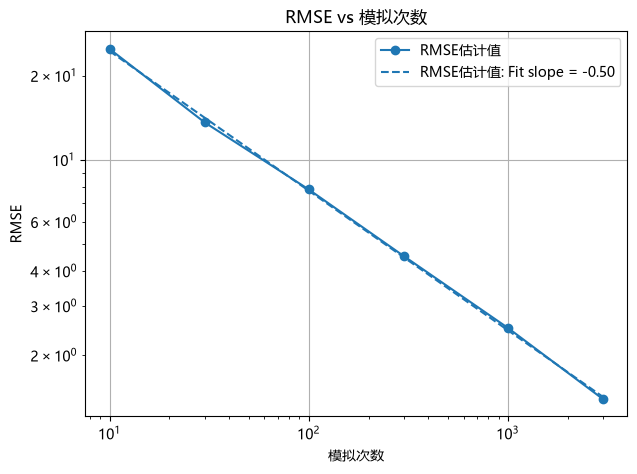

In [9]:
if __name__ == "__main__":
    sample_sizes = [10,30,100,300,1000,3000]
    # 无偏估计量的标准差等于 RMSE；这里用重复估计量的标准差近似。
    rmse_estimates = []
    for sample_size in sample_sizes:
        rmse_estimates.append(
            np.std(get_distribution(500, sample_size))
        )

    plot(sample_sizes, rmse_estimates, "loglog", "RMSE估计值", "模拟次数", "RMSE", "RMSE vs 模拟次数", True)


## 2.2 逆变换抽样

### 2.2.1 Bernoulli样本的生成

利用 Bernoulli 分布函数的广义逆
$$
F^{-}(u) = \begin{cases}
0, & 0 < u \leq 1-p, \\
1, & 1-p < u <1.
\end{cases}
$$

先生成均匀分布随机变量 $U \sim \mathcal{U}(0,1)$，再计算 $F^{-}(U) \sim \operatorname{Bernoulli}(p)$。

In [10]:
def bernoulli(p, rng: np.random.Generator | None = None):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    uniform_sample = random_source.random()
    # 将均匀样本代入 Bernoulli 分布函数的广义逆。
    return int(uniform_sample > 1 - p)


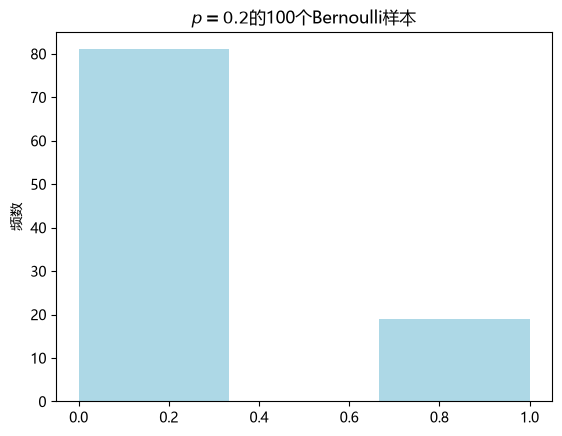

In [11]:
if __name__ == "__main__":
    samples = []

    for sample_index in range(100):
        samples.append(bernoulli(0.2))

    frequency_histogram(np.array(samples), title="$p=0.2$的100个Bernoulli样本", bins=3)


### 2.2.2 线性密度函数的样本生成

我们考虑密度函数为 $p(x) = 2x \mathbf{1}_{(0,1)}$ 的随机变量。通过计算可得其分布函数为
$$
F(x) = \begin{cases}
0, & x \leq 0 , \\
x^2, & 0 < x \leq 1 , \\
1,  & x > 1.
\end{cases}
$$
从而可以计算得到广义逆
$$
F^{-}(u) = \sqrt{u} \mathbf{1}_{(0,1)}(u)
$$
先生成均匀分布随机变量 $U \sim \mathcal{U}(0,1)$，再计算 $F^{-}(U)$。

In [12]:
def linear_PDF_inverseCDF(rng: np.random.Generator | None = None):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    uniform_sample = random_source.random()
    # F(x)=x²，因此广义逆为 sqrt(u)。
    return np.sqrt(uniform_sample)


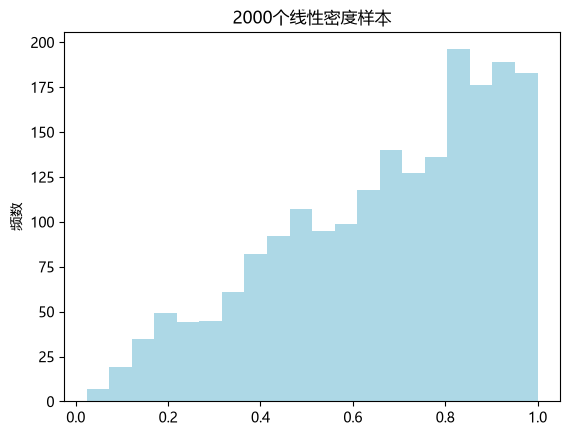

In [13]:
if __name__ == "__main__":
    samples = []

    for sample_index in range(2000):
        samples.append(linear_PDF_inverseCDF())

    frequency_histogram(np.array(samples), title="2000个线性密度样本", bins=20)


## 2.4 次序统计量构造分布

仍然考虑密度函数为 $p(x) = 2x \mathbf{1}_{(0,1)}$ 的随机变量 $X$ 。该随机变量是幂形式，可以通过均匀分布的次序统计量构造。

设 $U_1, U_2 \overset{\text{i.i.d.}}{\sim} \mathcal{U}(0,1)$，令 $U_{(2)} = \max\{U_1, U_2\}$。则对 $x \in (0,1) $ 有
$$
\mathbb{P}(U_{(2)} \leq x) = \mathbb{P}(U_1 \leq x, U_2 \leq x) = x^2.
$$
故 $U_{(2)}$ 的分布函数与 $X$ 相同，我们可以通过构造两个独立均匀分布的最大值得到 $X$ 。

In [14]:
def linear_PDF_orderstat(rng: np.random.Generator | None = None):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    uniform_sample_1, uniform_sample_2= random_source.random(), random_source.random()
    # 两个独立均匀样本的最大值，其分布函数为 x²。
    return max(uniform_sample_1,uniform_sample_2)


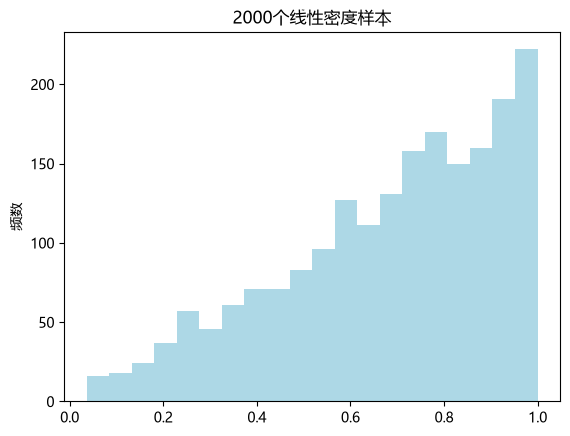

In [15]:
if __name__ == "__main__":
    samples = []

    for sample_index in range(2000):
        samples.append(linear_PDF_orderstat())

    frequency_histogram(np.array(samples), title="2000个线性密度样本", bins=20)


## 2.5 接受-拒绝抽样

仍然考虑密度函数为 $p(x) = 2x \mathbf{1}_{(0,1)}$ 的随机变量 $X$ 。取 $U \sim \mathcal{U}(0,1)$ 作为包络，其密度函数 $p_U(x) = \mathbf{1}_{(0,1)}$ 满足 $p(x) \leq 2p_U(x)$。

我们可以进行接受-拒绝采样：
- 生成 $ U, \widetilde{U} \overset{\text{i.i.d.}}{\sim} \mathcal{U}(0,1) $。
- 若 $\widetilde{U} \leq \dfrac{p(U)}{2p_U(U)}$，则接受 $U$ 作为 $X$ 的样本。
- 重复上述过程直到样本数满足要求

这里包络常数 $M=2$，因此平均接受率为 $\frac{1}{2}$，平均生成一个有效样本需要 2 个候选样本。

In [16]:
def linear_PDF_AccRej(rng: np.random.Generator | None = None):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    # 建议密度为均匀分布，包络常数为 2，候选值 x 的接受概率为 x。
    while True:
        candidate_sample = random_source.random()
        if random_source.random() <= candidate_sample:
            return candidate_sample


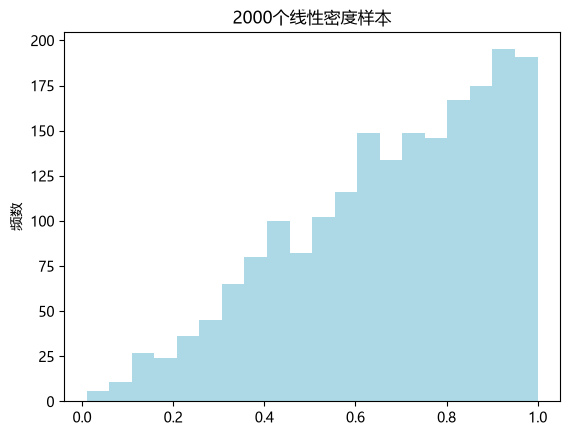

In [17]:
if __name__ == "__main__":
    samples = []

    for sample_index in range(2000):
        samples.append(linear_PDF_AccRej())

    frequency_histogram(np.array(samples), title="2000个线性密度样本", bins=20)


## 3.2 对偶变量法

### 3.2.1 对偶变量法缩减方差

考虑 Monte Carlo 积分
$$
\int_0^1 e^x \, dx = \mathbb{E}[e^U], \quad U \sim \mathcal{U}(0,1).
$$
被积函数 $e^x$ 是单调增的，故符合对偶变量法缩减方差条件。

我们比较一般 Monte Carlo 方法和对偶变量法的方差。固定进行500次实验，每次实验取1000个点计算 Monte Carlo 估计量，得到近似分布。最后比较二者的方差。

In [ ]:
def calculate_integral(func, samples: np.ndarray):
    # 保留原来的向量化包装，允许 func 按单个数值定义。
    vectorized_func = np.vectorize(func)
    return np.mean(vectorized_func(samples))

In [19]:
def generate_integral_distribution_uniform(
        func, 
        number_of_simulations:int, #计算积分次数
        sample_size: int, #每一次积分的样本点数量
    rng: np.random.Generator | None = None,
):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    # number_of_simulations 是重复次数 R；sample_size 是每次采样数量 N。
    integral_estimates = list()
    for replication_index in range(number_of_simulations):
        integral_estimates.append(calculate_integral(
            func, random_source.random(sample_size)
        ))

    return np.array(integral_estimates)

def generate_integral_distribution_antithetics(
        func,
        number_of_simulations: int,
        sample_size: int,
    rng: np.random.Generator | None = None,
):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    integral_estimates=list()
    for replication_index in range(number_of_simulations):
        uniform_samples = random_source.random(sample_size // 2)
        # 使用 N//2 对 (U,1-U)，总函数求值次数为 2*(N//2)。
        paired_samples = np.concatenate([uniform_samples, 1-uniform_samples])
        integral_estimates.append(calculate_integral(
            func, paired_samples
        ))

    return np.array(integral_estimates)


In [20]:
if __name__ == "__main__":
    uniform_estimates = generate_integral_distribution_uniform(
        np.exp, 500, 1000
    )
    antithetic_estimates = generate_integral_distribution_antithetics(
        np.exp, 500, 1000
    )
    print(
        f"一般MC方法均值{uniform_estimates.mean(): .4f}，方差{uniform_estimates.var(): .2e}"
    )
    print(
        f"对偶变量均值{antithetic_estimates.mean(): .4f}，方差{antithetic_estimates.var(): .2e}"
    )


一般MC方法均值 1.7192，方差 2.25e-04
对偶变量均值 1.7182，方差 8.84e-06


### 3.2.2 对偶变量不生效的情形

被积函数是单调能保证对偶变量负相关。不满足单调性的函数有可能使得对偶变量正相关，反而增加方差。我们考虑以下 Monte Carlo 积分：
$$
\int_0^1 x(1-x) \, dx.
$$
我们仍然固定进行500次实验，每次实验取1000个点计算 Monte Carlo 估计量，得到近似分布。最后比较一般方法和对偶变量的方差。

In [21]:
if __name__ == "__main__":
    uniform_estimates = generate_integral_distribution_uniform(
        lambda x: x*(1-x), 500, 1000
    )
    # x(1-x) 在 x 与 1-x 处取值相同，对偶样本没有提供新的信息。
    antithetic_estimates = generate_integral_distribution_antithetics(
        lambda x: x*(1-x), 500, 1000
    )
    print(
        f"一般MC方法均值{uniform_estimates.mean(): .4f}，方差{uniform_estimates.var(): .2e}"
    )
    print(
        f"对偶变量均值{antithetic_estimates.mean(): .4f}，方差{antithetic_estimates.var(): .2e}"
    )


一般MC方法均值 0.1668，方差 5.45e-06
对偶变量均值 0.1668，方差 1.20e-05


## 3.3 分层抽样

仍然考虑Monte Carlo 积分
$$
\int_0^1 e^x \, dx = \mathbb{E}[e^U], \quad U \sim \mathcal{U}(0,1).
$$
我们将 $[0,1]$ 平均分割成多份，在每份上分别生成样本，观察方差随分割数量的变化。

In [22]:
def calculate_integral_stratification(func, samples: np.ndarray):
    vectorized_func = np.vectorize(func)
    
    layers = samples.shape[0]
    
    # 每一层内部求平均
    stratum_means = np.mean(vectorized_func(samples), axis=1)
    
    # 等宽分层的权重均为 1/layers，所以对各层均值再求平均。
    return np.mean(stratum_means)


def generate_integral_distribution_stratification(
        func,
        number_of_simulations: int,  # 计算积分次数
        sample_size: int,            # 每一次积分的样本点数量
        layers: int,                  # 层数
    rng: np.random.Generator | None = None,
):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    integral_estimates = list()

    # 保留原来的整除分配，实际总样本数为 layers*(sample_size//layers)。
    samples_per_layer = sample_size // layers

    for _ in range(number_of_simulations):

        # 分层生成样本
        samples = (
            np.arange(layers)[:, None]
            + random_source.random(
                (layers, samples_per_layer)
            )
        ) / layers

        integral_estimates.append(
            calculate_integral_stratification(
                func,
                samples
            )
        )

    return np.array(integral_estimates)


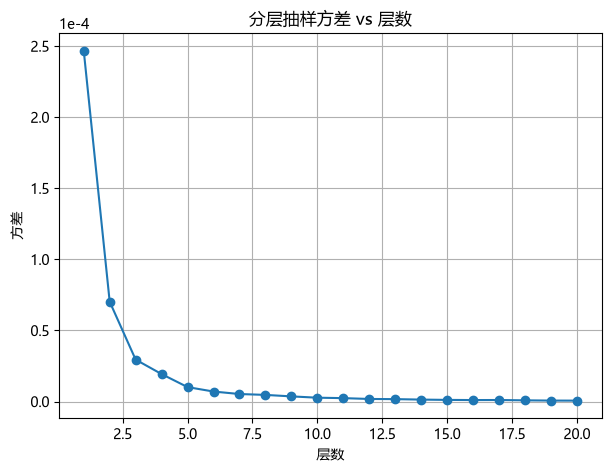

In [23]:
if __name__ == "__main__":
    variance_estimates = list()
    for n_layers in range(1,21):
        variance_estimates.append(
            generate_integral_distribution_stratification(
                np.exp, 500, 1000, n_layers
            ).var()
        )

    plot(
        np.arange(1,21),
        np.array(variance_estimates),
        ylabel="方差",
        xlabel="层数",
        title="分层抽样方差 vs 层数"
    )


## 3.4 重要性采样

### 3.4.1 重要性采样缩减方差

仍然考虑Monte Carlo 积分
$$
\int_0^1 e^x \, dx = \mathbb{E}[e^U], \quad U \sim \mathcal{U}(0,1).
$$

我们采用一个更加贴合 $e^x$ 的密度 $q(x)$ 作为建议密度，以减小 $\frac{e^x}{q(x)}$ 在建议分布下的方差。这里我们考虑未归一化密度 $\widetilde{q}(x) = 1 + 2x$ ，归一化有
$$
q(x) = \frac{1}{2}(1+2x).
$$
可以计算其广义逆为
$$
F^{-}(u) = -\frac{1}{2} + \frac{1}{2} \sqrt{1+8u}
$$
因此我们可以使用逆变换法生成服从 $p$ 的样本，进而进行重要性采样。

我们固定进行500次实验，每次实验取1000个点计算 Monte Carlo 估计量，得到近似分布。最后比较二者的方差。

In [24]:
def generate_integral_distribution_IS(
        func,
        number_of_simulations: int,  # 计算积分次数
        sample_size: int,            # 每一次积分的样本点数量
        generator,                    # 样本生成器
    rng: np.random.Generator | None = None,
):
    # 不传 rng 时兼容原来的无参数生成器；传入时生成器需支持 rng 参数。
    integral_estimates=list()
    for _ in range(number_of_simulations):
        proposal_samples = np.array([
            generator() if rng is None else generator(rng=rng)
            for _ in range(sample_size)
        ])
        integral_estimates.append(calculate_integral(
            func, proposal_samples
        ))

    return np.array(integral_estimates)

def gen_IS(rng: np.random.Generator | None = None):
    # rng 可选；不传时沿用 np.random，兼容原来的调用与全局种子。
    random_source = np.random if rng is None else rng
    # 建议密度为 (1+2x)/2；这里使用其分布函数的广义逆。
    return -0.5+0.5*np.sqrt(1+8*random_source.random())


In [25]:
if __name__ == "__main__":
    uniform_estimates = generate_integral_distribution_uniform(
        np.exp, 500, 1000
    )
    # func 已包含重要性权重 1/q(x)，估计的是 exp(x)/q(x) 的均值。
    importance_estimates = generate_integral_distribution_IS(
        lambda x: np.exp(x) / (0.5*(1+2*x)), 
        500, 1000, 
        gen_IS
    )
    print(
        f"一般MC方法均值{uniform_estimates.mean(): .4f}，方差{uniform_estimates.var(): .2e}"
    )
    print(
        f"重要性采样均值{importance_estimates.mean(): .4f}，方差{importance_estimates.var(): .2e}"
    )


一般MC方法均值 1.7183，方差 2.30e-04
重要性采样均值 1.7183，方差 4.73e-06


### 3.4.2 计算正态分布尾概率

设 $Z \sim \mathcal{N}(0,1)$，估计 $\mathbb P(Z>5)$。

先将目标写成积分
$$
\mathbb P(Z>5) = \int_5^{+\infty} \frac{1}{\sqrt{2\pi}}e^{-\frac{x^2}{2}}\, dx 
= \int_{\mathbb R} \frac{1}{\sqrt{2\pi}}e^{-\frac{x^2}{2}}\mathbf{1}_{(5, +\infty)}\, dx.
$$

注意到该积分的密度全部集中在右侧，如果直接使用正态总体，落在尾部的样本会极少，产生较大的误差。因此可以采用重要性采样，使用 $\mathcal N(5,1)$ 作为建议分布。

固定进行500次实验，每次实验取100/300/1000/3000/10000/30000/100000个点计算 Monte Carlo 估计量，得到近似分布，最后比较二者的RMSE。取近似真值 $\mathbb P(Z>5) = 1 - \Phi(5) \approx 2.8665 \times 10^{-7}$

N =  100 | 普通MC均值 = 0.0000e+00 | IS均值 = 2.8595e-07 | 普通MC非零次数 = 0/500
N =  300 | 普通MC均值 = 0.0000e+00 | IS均值 = 2.8882e-07 | 普通MC非零次数 = 0/500
N = 1000 | 普通MC均值 = 0.0000e+00 | IS均值 = 2.8473e-07 | 普通MC非零次数 = 0/500
N = 3000 | 普通MC均值 = 0.0000e+00 | IS均值 = 2.8539e-07 | 普通MC非零次数 = 0/500
N = 10000 | 普通MC均值 = 4.0000e-07 | IS均值 = 2.8673e-07 | 普通MC非零次数 = 2/500
N = 30000 | 普通MC均值 = 0.0000e+00 | IS均值 = 2.8674e-07 | 普通MC非零次数 = 0/500
N = 100000 | 普通MC均值 = 3.0000e-07 | IS均值 = 2.8671e-07 | 普通MC非零次数 = 14/500


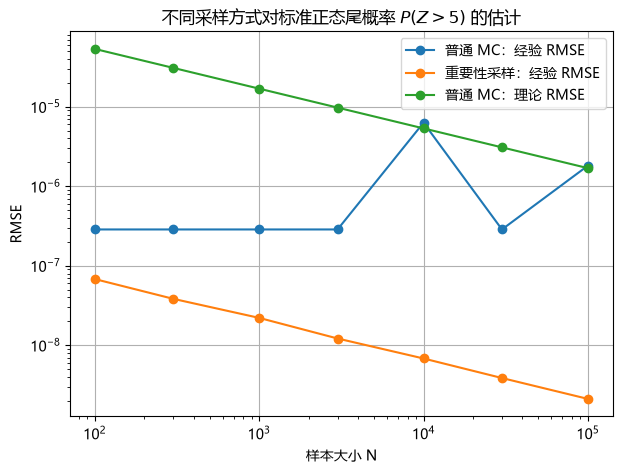

In [26]:
if __name__ == "__main__":
    TRUE_PROBABILITY = 2.866515718791933e-7 #标准正态分布P(Z > 5)
    sample_sizes = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
    n_replications = 500 #每个样本量下独立重复实验的次数

    np.random.seed(SEED) #固定随机种子，方便复现实验

    rmse_mc = list()
    rmse_is = list()

    for sample_size in sample_sizes:
        estimates_mc = list()
        estimates_is = list()

        for _ in range(n_replications):
            #普通MC：从标准正态分布生成sample_size个样本
            samples = np.random.normal(size=sample_size)

            estimates_mc.append(
                np.mean(samples > 5)
            )

            #重要性采样：从N(5,1)生成sample_size个样本
            samples = np.random.normal(loc=5, size=sample_size)

            #密度比phi(x)/q(x) = exp(-5*x + 12.5)
            estimates_is.append(
                np.mean((samples > 5) * np.exp(-5*samples + 12.5))
            )

        #转成数组，每个元素是一次独立实验得到的概率估计值
        estimates_mc = np.asarray(estimates_mc)
        estimates_is = np.asarray(estimates_is)

        #使用真实值计算两种方法的经验RMSE
        rmse_mc.append(
            np.sqrt(np.mean((estimates_mc - TRUE_PROBABILITY)**2))
        )
        rmse_is.append(
            np.sqrt(np.mean((estimates_is - TRUE_PROBABILITY)**2))
        )

        #查看估计均值和普通MC中非零估计的次数
        print(
            f"N = {sample_size:4d} | "
            f"普通MC均值 = {estimates_mc.mean():.4e} | "
            f"IS均值 = {estimates_is.mean():.4e} | "
            f"普通MC非零次数 = "
            f"{np.count_nonzero(estimates_mc)}/{n_replications}"
        )

    #普通MC的理论RMSE：sqrt(p*(1-p)/N)
    rmse_theoretical = np.sqrt(
        TRUE_PROBABILITY * (1 - TRUE_PROBABILITY) / sample_sizes
    )

    #同时绘制两种方法的经验RMSE，以及普通MC的理论RMSE
    plot(
        x=sample_sizes,
        y=np.array([rmse_mc, rmse_is, rmse_theoretical]),
        figtype="loglog",
        label=[
            "普通 MC：经验 RMSE",
            "重要性采样：经验 RMSE",
            "普通 MC：理论 RMSE"
        ],
        xlabel="样本大小 N",
        ylabel="RMSE",
        title="不同采样方式对标准正态尾概率 $P(Z > 5)$ 的估计",
        fit_slope=False
    )
